In [1]:
!pip install xgboost 

In [2]:
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import RandomizedSearchCV
import matplotlib.pyplot as plt
import pandas as pd
import pickle

In [3]:
df = pd.read_csv(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Data/Processed/cleaned_dataset.csv")
df.head()
df = df.drop(columns=["LULC"])

In [4]:
# One hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore")
encoded = ohe.fit_transform(df[["LULC_Name"]])

encoded_df = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["LULC_Name"]),
    index = df.index
)

df = pd.concat([df.drop(columns=["LULC_Name"]),encoded_df], axis=1)

In [5]:
df.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'LST', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope',
       'WindSpeed', 'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='str')

In [6]:
df.to_csv(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Data/Processed/final_dataset.csv", index=False)

In [7]:
X = df.drop(columns=["LST"])
y = df["LST"]

In [8]:
X.columns

Index(['Latitude', 'Longitude', 'AirTemp', 'DistanceToWater', 'Elevation',
       'Humidity', 'MNDWI', 'NDBI', 'NDVI', 'Population', 'Slope', 'WindSpeed',
       'LULC_Name_Built Area', 'LULC_Name_Crops',
       'LULC_Name_Flooded Vegetation', 'LULC_Name_Grass', 'LULC_Name_Shrub',
       'LULC_Name_Trees', 'LULC_Name_Water'],
      dtype='str')

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=43
)

In [10]:
model = xgb.XGBRegressor()
model.fit(X_train, y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [11]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

In [12]:
print(f"RMSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"RMSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")

RMSE of training data = 0.6634855119639428
RMSE of testing data = 1.3229528273565323
r2_score of training data = 0.961961869974223
r2_score of testing data = 0.8445910692860628


# Hyperparameter tuning

In [13]:
# param_grid = {
#     "n_estimators" : [100,200,300,400,500],
#     "max_depth" : [3, 4, 5, 6, 8, 10],
#     "learning_rate" : [0.01, 0.03, 0.05, 0.1, 0.2],
#     "min_child_weight" : [1, 3, 5, 7, 10],
#     "gamma" : [0, 0.1, 0.3, 0.5, 1],
#     "subsample": [0.7, 0.8, 0.9],
#     "colsample_bytree": [0.7, 0.8, 0.9],
#     "reg_alpha": [0, 0.01, 0.1],
#     "reg_lambda": [1, 2, 5]
# }

# random_search = RandomizedSearchCV(
#     model,
#     param_grid,
#     scoring="r2",
#     n_iter=40,
#     cv=5,
#     n_jobs=-1
# )

# random_search.fit(X_train, y_train)
# best_r2_score = random_search.best_score_
# best_param = random_search.best_params_

In [14]:
# print(best_r2_score)
# print(best_param)

In [15]:
best_model = xgb.XGBRegressor(
    n_estimators=400,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.9,
    reg_lambda=1,
    reg_alpha=0,
    min_child_weight=1,
    gamma=0,
    colsample_bytree=0.8
)
best_model.fit(X_train,y_train)
y_pred_train = best_model.predict(X_train)
y_pred_test = best_model.predict(X_test)

In [16]:
print(f"RMSE of training data = {root_mean_squared_error(y_train, y_pred_train)}")
print(f"RMSE of testing data = {root_mean_squared_error(y_test, y_pred_test)}")

print(f"r2_score of training data = {r2_score(y_train, y_pred_train)}")
print(f"r2_score of testing data = {r2_score(y_test, y_pred_test)}")
print(f"mean absolute error of testing data = {mean_absolute_error(y_test, y_pred_test)}")

RMSE of training data = 0.7834523350418601
RMSE of testing data = 1.273799620710124
r2_score of training data = 0.9469626972815611
r2_score of testing data = 0.8559247157134637
mean absolute error of testing data = 0.9680108433533093


In [17]:
print(best_model.feature_importances_)

[0.01732007 0.0714371  0.02726389 0.02346464 0.01239731 0.04225864
 0.06358595 0.2532256  0.06702273 0.02712429 0.00638797 0.01871555
 0.06248045 0.03035703 0.00270719 0.         0.01339438 0.0535879
 0.20726939]


In [18]:
importance = pd.DataFrame({
    "Features" : X.columns,
    "Importance" : best_model.feature_importances_
})
importance = importance.sort_values(by="Importance", ascending=False)
importance

,Features,Importance
7,NDBI,0.253226
18,LULC_Name_Water,0.207269
1,Longitude,0.071437
8,NDVI,0.067023
6,MNDWI,0.063586
12,LULC_Name_Built Area,0.062480
17,LULC_Name_Trees,0.053588
5,Humidity,0.042259
13,LULC_Name_Crops,0.030357
2,AirTemp,0.027264


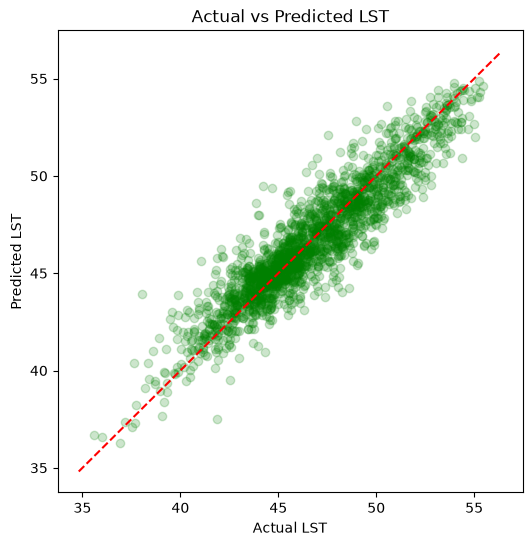

In [19]:
# Actual vs Predictedplt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_test,c="green", alpha=0.2)
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
plt.xlabel("Actual LST")
plt.ylabel("Predicted LST")
plt.title("Actual vs Predicted LST")
plt.show()

# SHAP

In [20]:
!pip install shap

In [21]:
import shap

In [22]:
explainer = shap.TreeExplainer(best_model)

In [23]:
with open(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Streamlit/shap_explainer.pkl", "wb") as f:
    pickle.dump(explainer, f)

In [24]:
shap_values = explainer.shap_values(X_test)

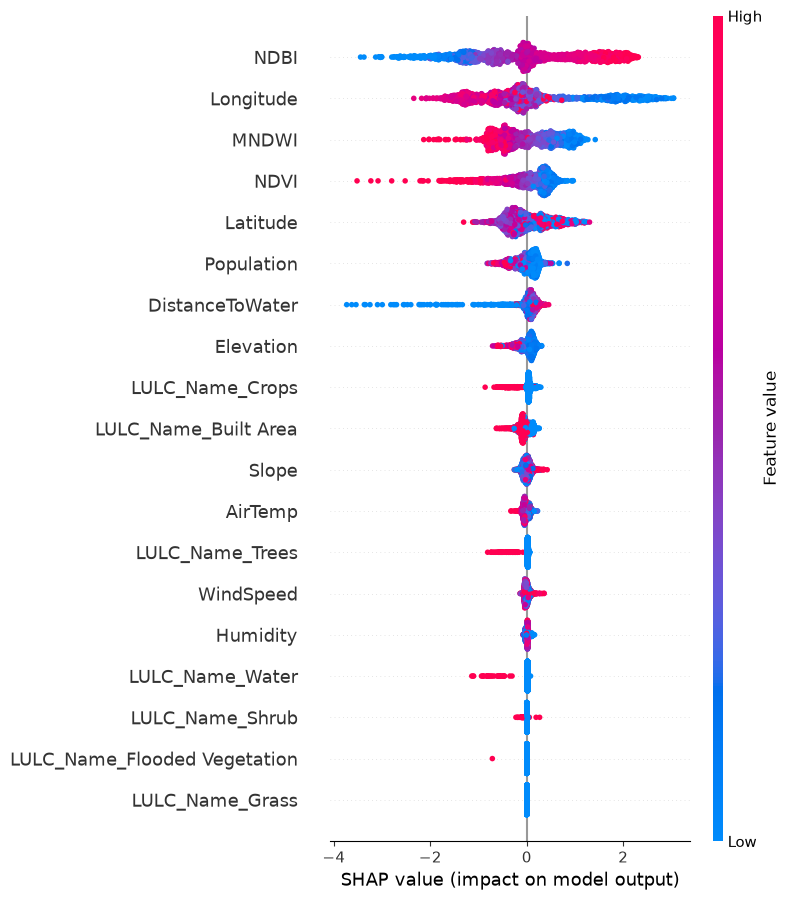

In [25]:
shap.summary_plot(shap_values, X_test)

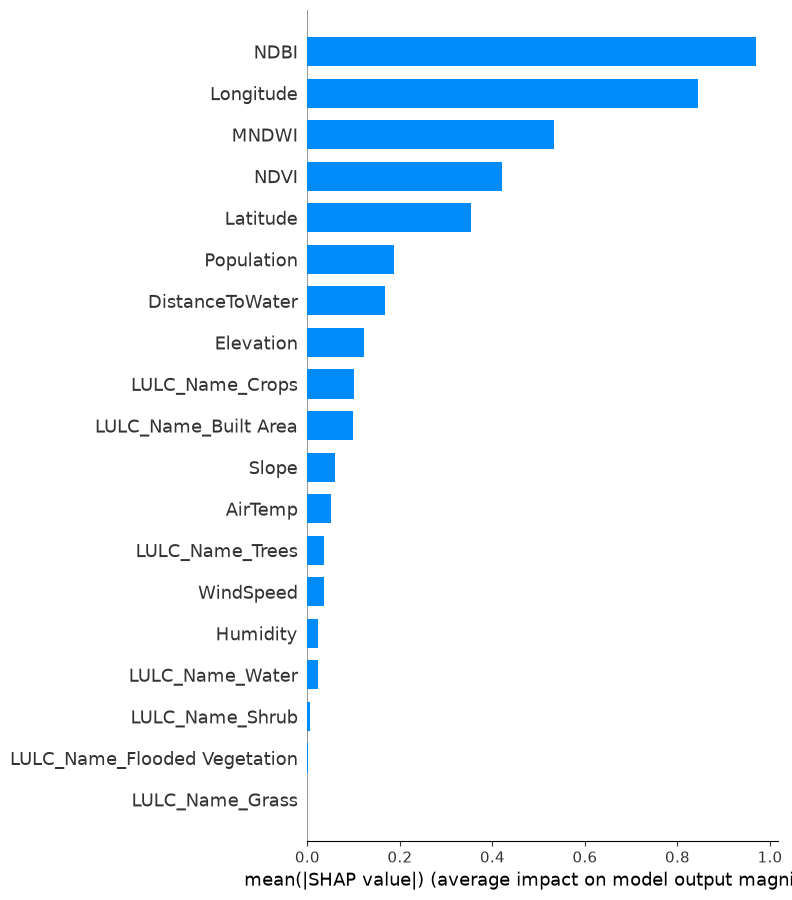

In [26]:
shap.summary_plot(
    shap_values,
    X_test,
    plot_type="bar"
)

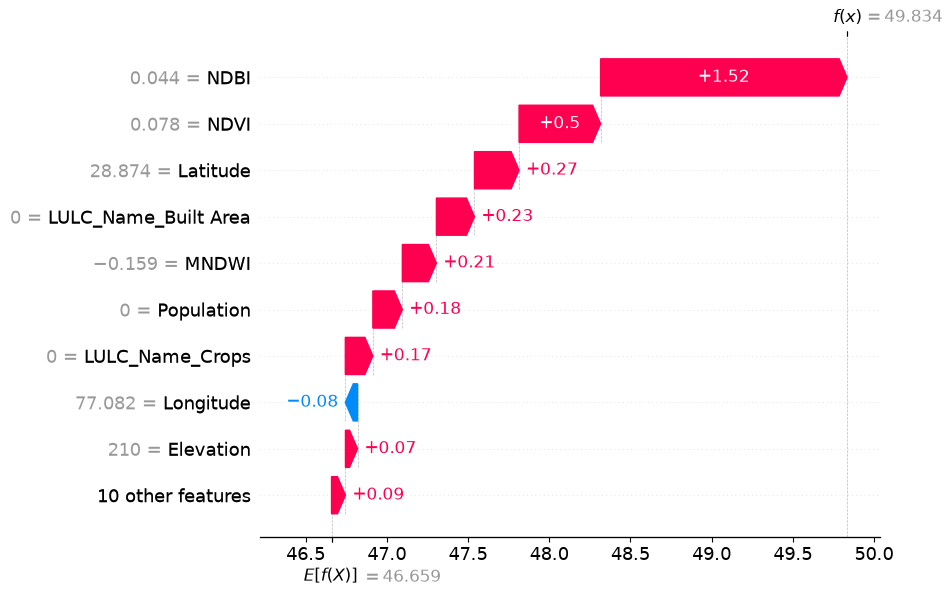

In [27]:
sample = 0
shap.plots.waterfall(
    explainer(X_test.iloc[[sample]])[0]
)

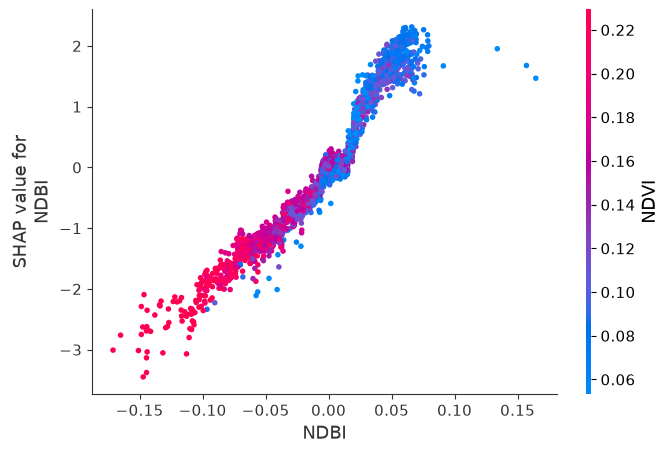

In [28]:
shap.dependence_plot(
    "NDBI",
    shap_values,
    X_test
)

In [29]:
with open(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Streamlit/best_model.pkl", "wb") as f:
    pickle.dump(best_model,f)

In [30]:
with open(r"/Users/kashvivirmani/Desktop/Delhi_UHI_Project/Streamlit/features_names.pkl", "wb") as file:
    pickle.dump(X.columns.tolist(),file)